5000
-119.68074562404193
Time Taken until now: 0.43038421869277954 minutes
10000
-157.80702722057467
Time Taken until now: 0.8557552655537923 minutes
15000
-61.68001334525647
Time Taken until now: 1.344080380598704 minutes
20000
-34.23451834402246
Time Taken until now: 1.7821825861930847 minutes
25000
-8.022522241890611
Time Taken until now: 2.4088093519210814 minutes
30000
11.224042291293364
Time Taken until now: 3.470821571350098 minutes
35000
17.288320884278818
Time Taken until now: 22.56271148522695 minutes
40000
34.26272684220647
Time Taken until now: 24.57665496269862 minutes
45000
49.17986554556265
Time Taken until now: 26.733394237359366 minutes
50000
43.93326378793871
Time Taken until now: 28.699907406171164 minutes
55000
36.395012548975835
Time Taken until now: 30.60129106839498 minutes
60000
36.705038346787504
Time Taken until now: 32.2705859820048 minutes
65000
49.23335362291817
Time Taken until now: 33.9701393644015 minutes
70000
32.28320304397248
Time Taken until now: 35.

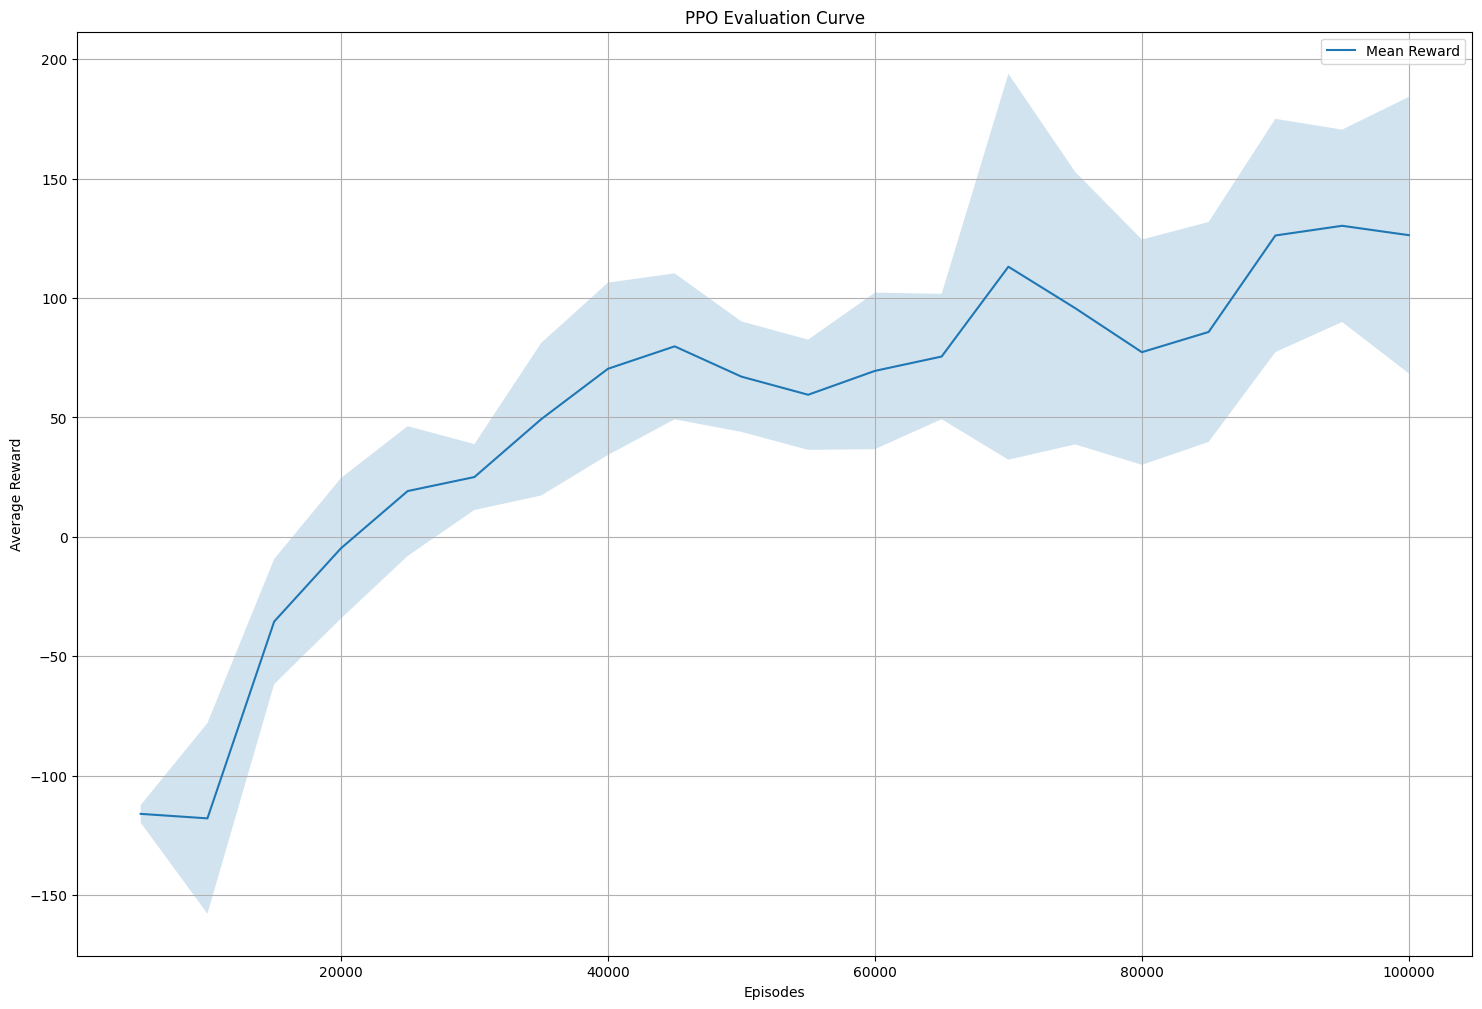

In [10]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 12
T_horizon = 2048
batch_size = 64
entropy_coef_i = 0.01
entropy_coef_e = 0.0005
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

5000
-114.63967281420543
Time Taken until now: 0.6599441965421041 minutes
10000
-67.76727410429547
Time Taken until now: 1.513076122601827 minutes
15000
-27.930322908951037
Time Taken until now: 3.609736422697703 minutes
20000
-13.436355552902658
Time Taken until now: 5.5783862193425495 minutes
25000
8.95271926402483
Time Taken until now: 7.785939153035482 minutes
30000
23.96443778853672
Time Taken until now: 12.701456995805104 minutes
35000
36.48724188697035
Time Taken until now: 17.93369108835856 minutes
40000
23.685151083913944
Time Taken until now: 22.0175217350324 minutes
45000
48.34388363981555
Time Taken until now: 25.45111310084661 minutes
50000
53.1060407581947
Time Taken until now: 28.530354702472685 minutes
55000
57.15825468679294
Time Taken until now: 30.945507780710855 minutes
60000
25.376661297523984
Time Taken until now: 32.76024769941966 minutes
65000
20.602595283134146
Time Taken until now: 34.68328145345052 minutes
70000
39.364672300744246
Time Taken until now: 36.938

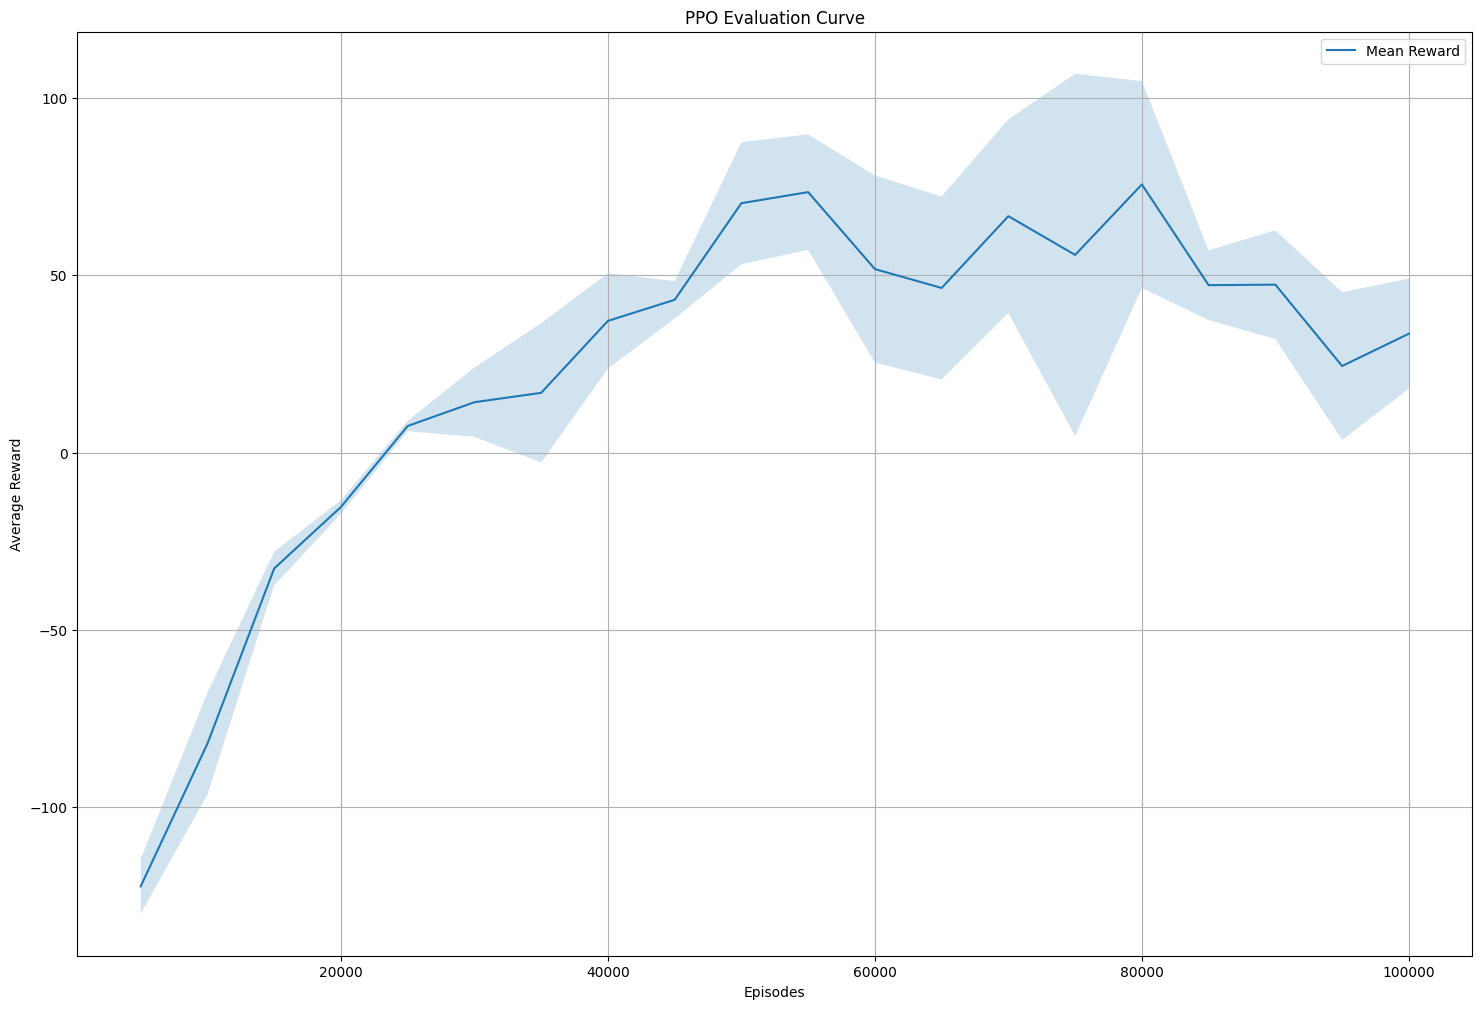

In [11]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 12
T_horizon = 2048
batch_size = 32
entropy_coef_i = 0.01
entropy_coef_e = 0.0005
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

5000
-75.2996100390947
Time Taken until now: 0.8230636954307556 minutes
10000
-7.035050823828577
Time Taken until now: 1.9268622716267905 minutes
15000
12.287277134590015
Time Taken until now: 2.9922723452250164 minutes
20000
15.959556806107871
Time Taken until now: 4.205284897486369 minutes
25000
37.334623178267655
Time Taken until now: 5.333472514152527 minutes
30000
13.105413286807043
Time Taken until now: 6.767564678192139 minutes
35000
126.42433482432976
Time Taken until now: 7.970283997058869 minutes
40000
-2.3500794827881317
Time Taken until now: 9.216432185967763 minutes
45000
-25.15798037265345
Time Taken until now: 10.152704970041912 minutes
50000
36.27360240342665
Time Taken until now: 11.833016339937846 minutes
55000
62.228721229037134
Time Taken until now: 14.23254576921463 minutes
60000
32.73950956475196
Time Taken until now: 15.967973299821217 minutes
65000
4.855341376899549
Time Taken until now: 17.00163663625717 minutes
70000
51.44120233118355
Time Taken until now: 18.

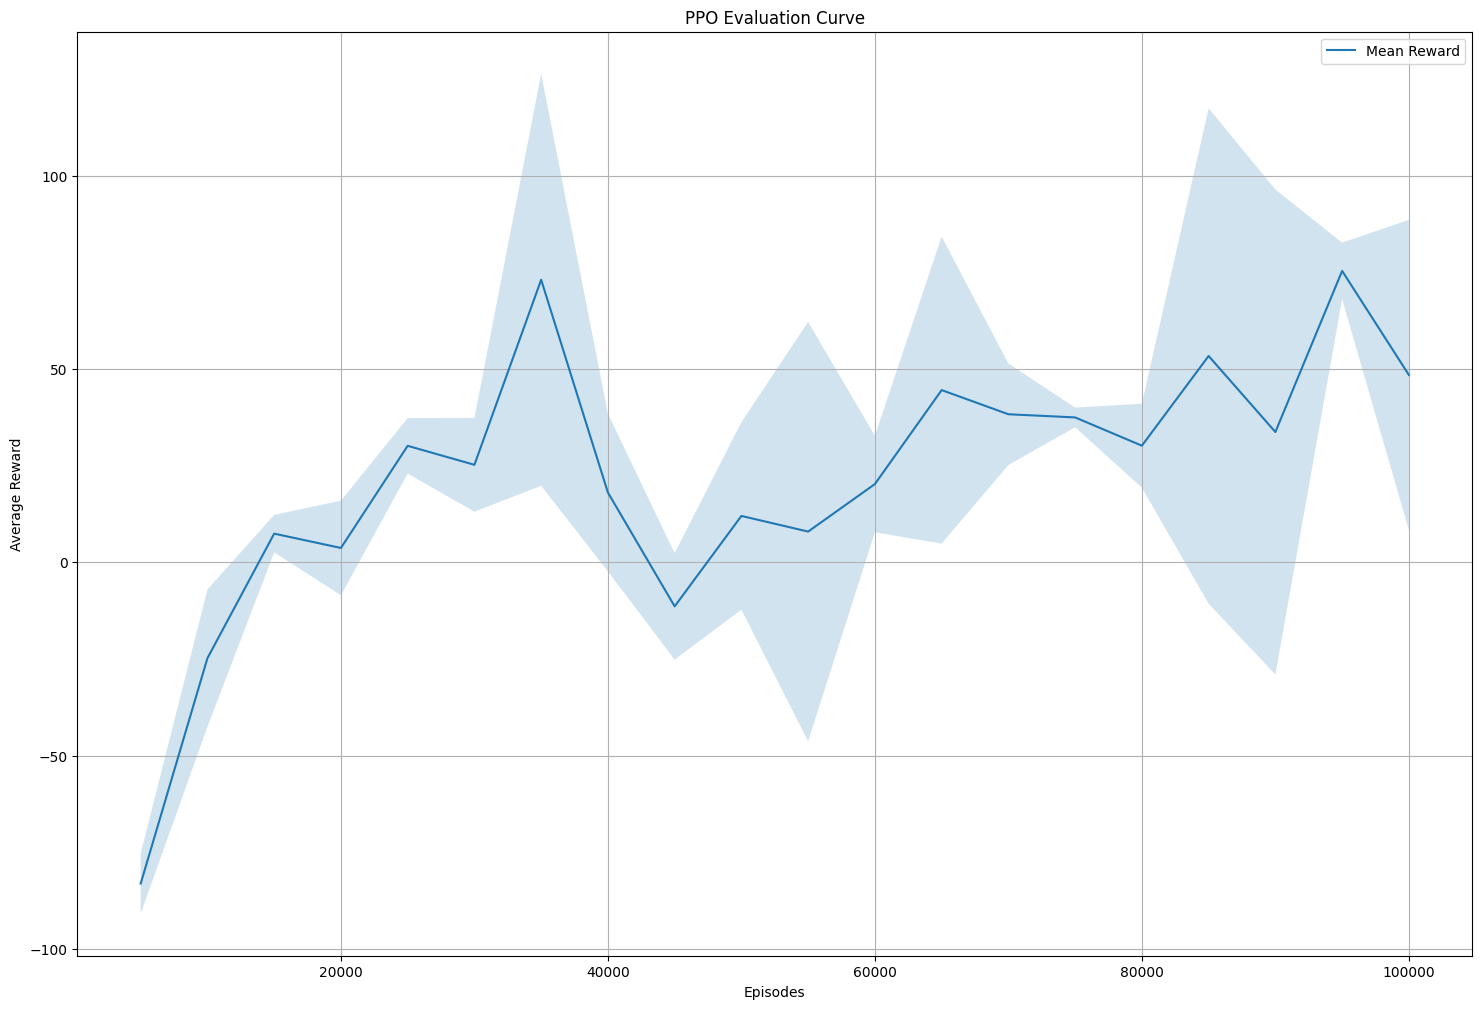

In [12]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 20
T_horizon = 1024
batch_size = 32
entropy_coef_i = 0.01
entropy_coef_e = 0.0005
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

5000
-110.17207687578471
Time Taken until now: 0.855613648891449 minutes
10000
-63.10280903087109
Time Taken until now: 1.7316112677256266 minutes
15000
-24.629782172476762
Time Taken until now: 2.9235511501630147 minutes
20000
-18.08596121904319
Time Taken until now: 3.911689309279124 minutes
25000
3.2656073815729036
Time Taken until now: 5.143510417143504 minutes
30000
17.7152356294357
Time Taken until now: 6.497672478357951 minutes
35000
27.75279960794458
Time Taken until now: 8.278345143795013 minutes
40000
-16.31024432458438
Time Taken until now: 9.652712293465932 minutes
45000
9.584095582134458
Time Taken until now: 11.362779637177786 minutes
50000
5.761603370694007
Time Taken until now: 12.837159645557403 minutes
55000
2.644280775784008
Time Taken until now: 14.308660566806793 minutes
60000
3.537962108342709
Time Taken until now: 15.88867913087209 minutes
65000
1.164413095130024
Time Taken until now: 17.206199868520102 minutes
70000
12.930213796076114
Time Taken until now: 18.93

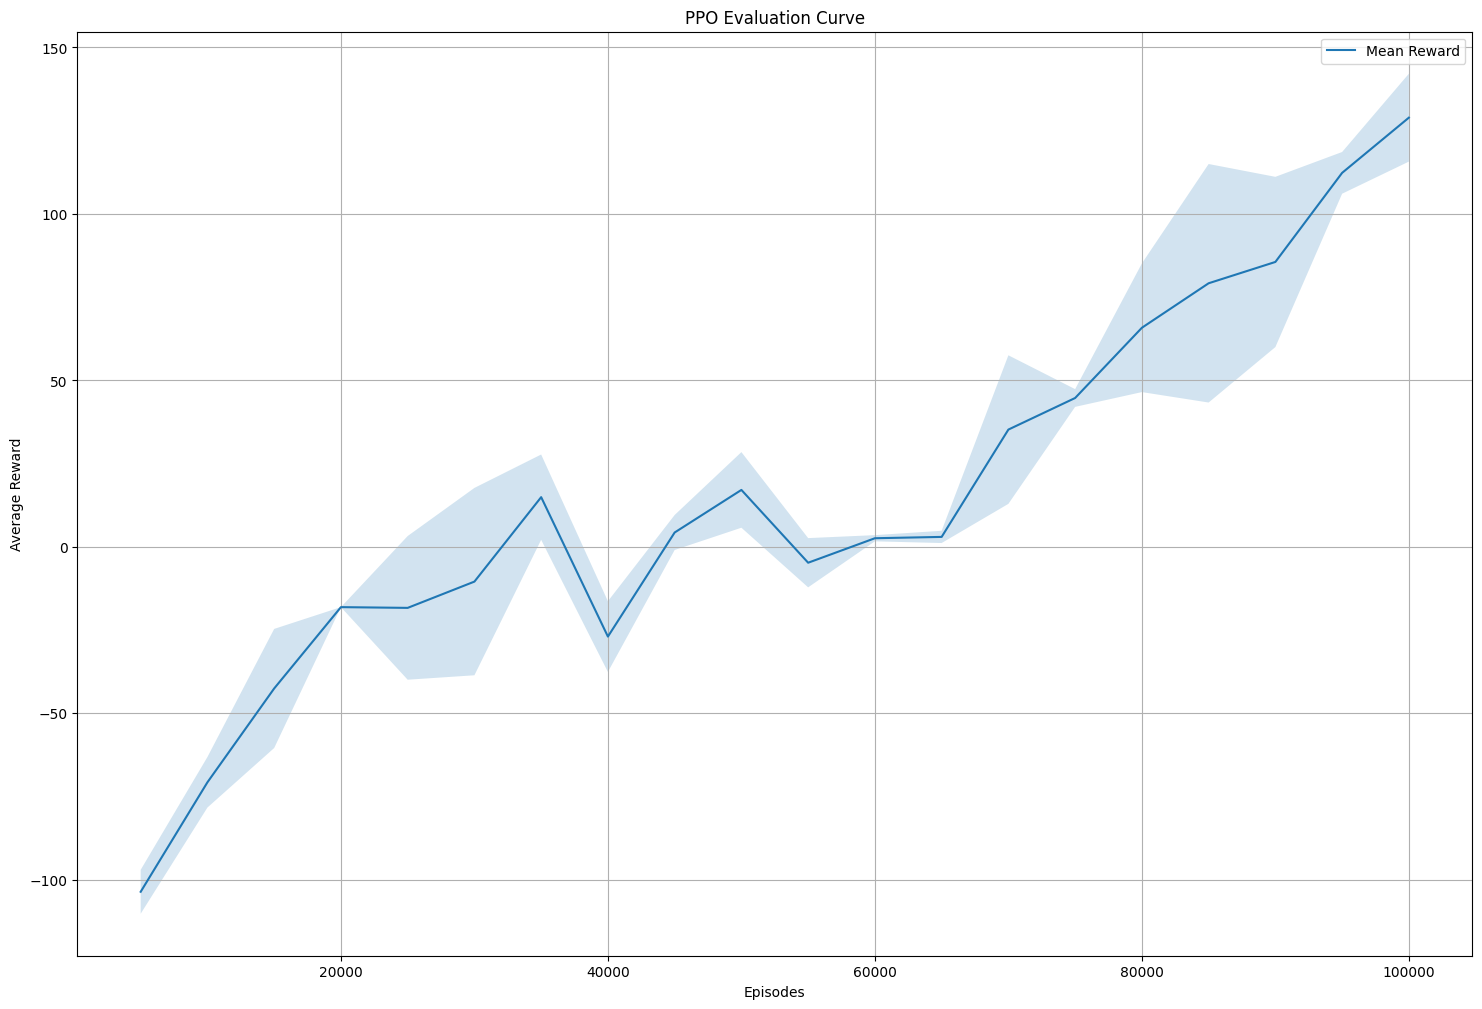

In [13]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 32
T_horizon = 2048
batch_size = 32
entropy_coef_i = 0.01
entropy_coef_e = 0.0005
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

5000
-137.16137772194352
Time Taken until now: 0.7292147755622864 minutes
10000
-83.88554875974181
Time Taken until now: 1.9128295063972474 minutes
15000
-63.343772312179965
Time Taken until now: 2.6700887282689414 minutes
20000
-51.604744101564336
Time Taken until now: 3.886735200881958 minutes
25000
-17.95301790791547
Time Taken until now: 5.117577755451203 minutes
30000
-9.133704386085556
Time Taken until now: 5.9631349563598635 minutes
35000
-35.35557222184189
Time Taken until now: 7.181124567985535 minutes
40000
-3.836364961116008
Time Taken until now: 8.418735416730245 minutes
45000
-7.5731485496450945
Time Taken until now: 9.315036801497142 minutes
50000
22.236597471125204
Time Taken until now: 11.039375102519989 minutes
55000
24.802720469343125
Time Taken until now: 12.55316930214564 minutes
60000
18.551930231848033
Time Taken until now: 14.689427649974823 minutes
65000
54.54068705658599
Time Taken until now: 16.93907058238983 minutes
70000
70.6188162662131
Time Taken until now

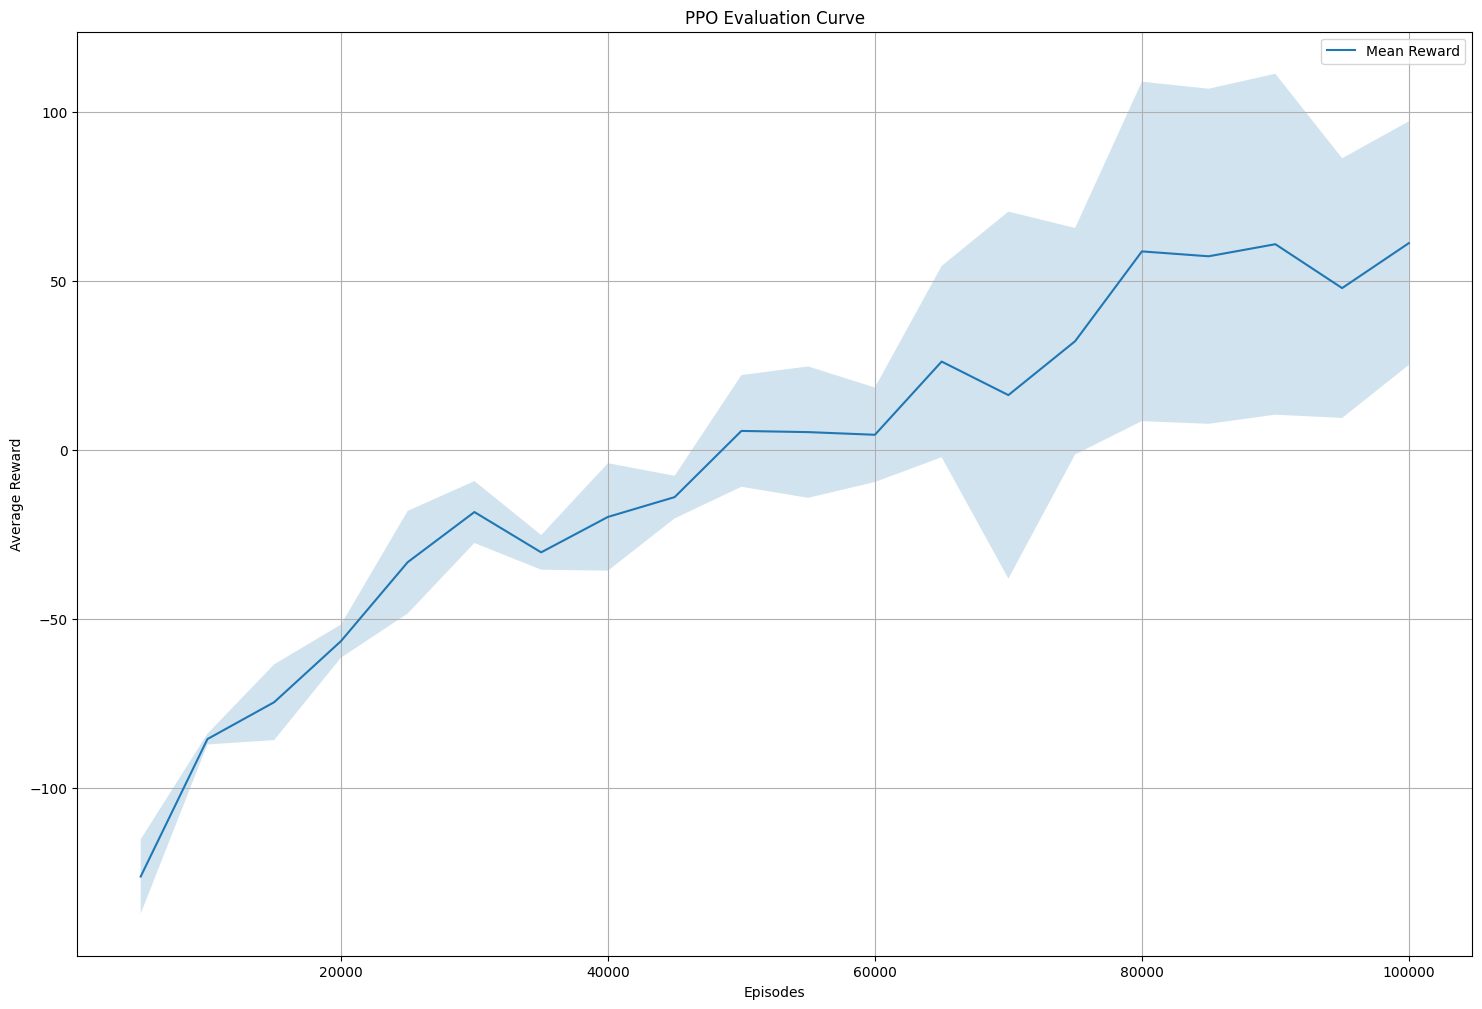

In [14]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 32
T_horizon = 3072
batch_size = 32
entropy_coef_i = 0.01
entropy_coef_e = 0.0005
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

5000
-87.23252618089204
Time Taken until now: 0.8556203603744507 minutes
10000
-86.187457994966
Time Taken until now: 1.745485277970632 minutes
15000
-29.16683372268561
Time Taken until now: 2.940589725971222 minutes
20000
-8.686297026973685
Time Taken until now: 3.9336679418881735 minutes
25000
-8.10106882243387
Time Taken until now: 5.233421917756399 minutes
30000
-2.860755748385177
Time Taken until now: 6.291785140832265 minutes
35000
15.211052806828274
Time Taken until now: 7.718891088167826 minutes
40000
18.38649570818026
Time Taken until now: 8.883642482757569 minutes
45000
-20.645406612621194
Time Taken until now: 10.027934555212656 minutes
50000
-70.11504304318949
Time Taken until now: 11.742639068762461 minutes
55000
11.754455250209967
Time Taken until now: 13.434815994898479 minutes
60000
46.20731015138956
Time Taken until now: 15.57483690182368 minutes
65000
26.44543249711752
Time Taken until now: 17.04427089691162 minutes
70000
-9.583279949469375
Time Taken until now: 18.75

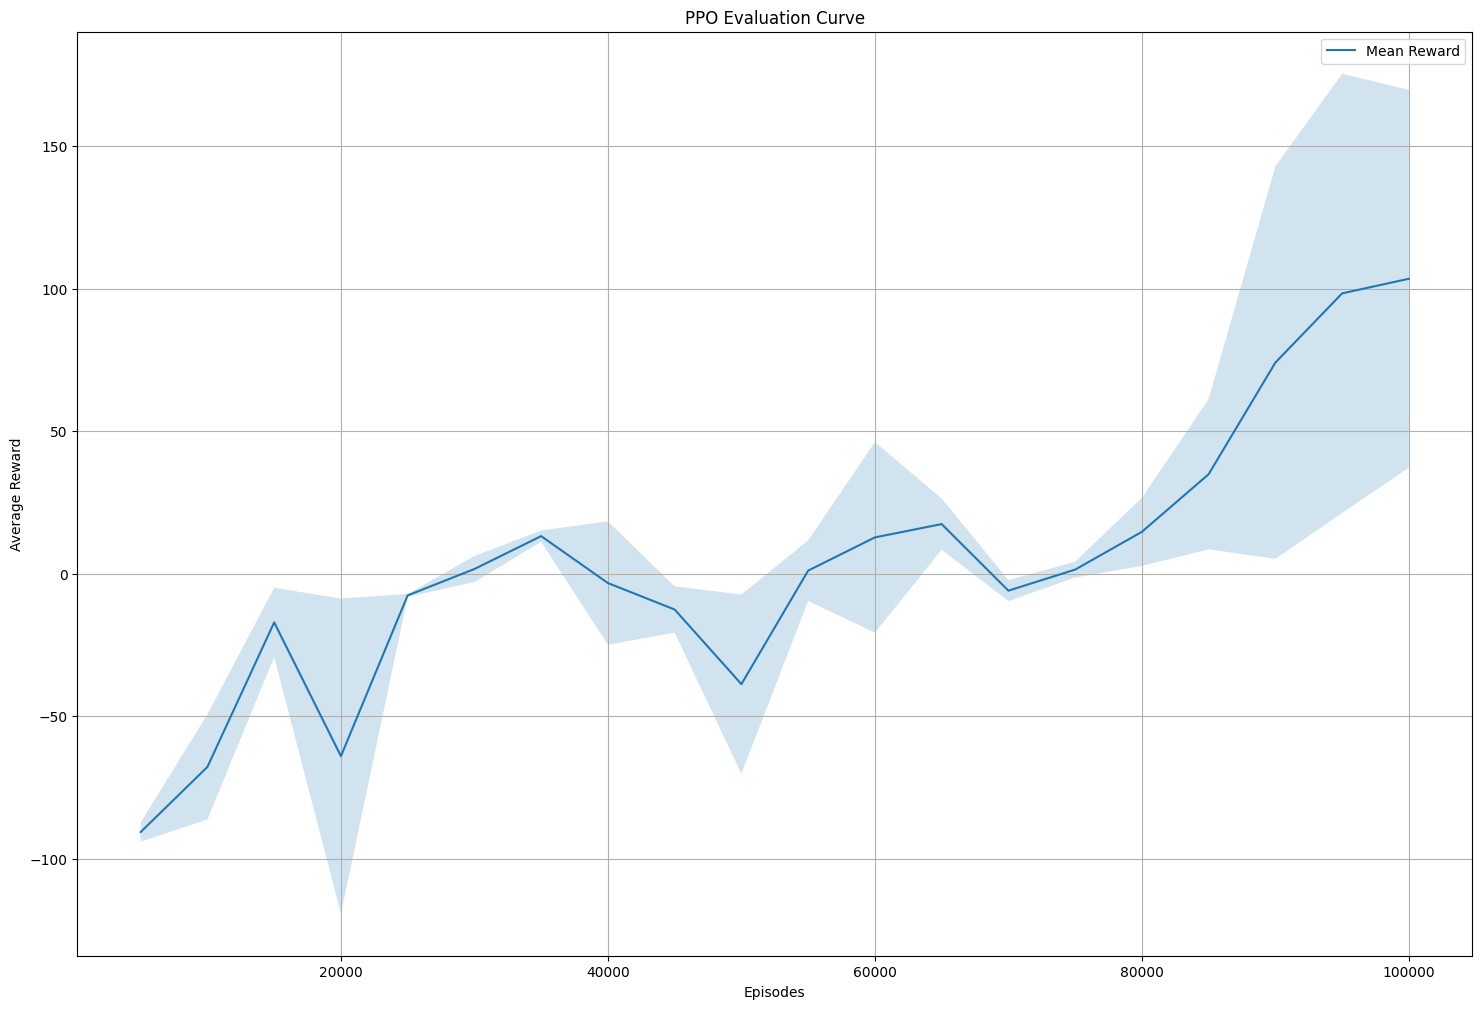

In [15]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 32
T_horizon = 2048
batch_size = 32
entropy_coef_i = 0.01
entropy_coef_e = 0.001
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

5000
-123.0689921285586
Time Taken until now: 0.8316774090131124 minutes
10000
-62.41275767435208
Time Taken until now: 1.6055452346801757 minutes
15000
-26.21900625754733
Time Taken until now: 2.559263904889425 minutes
20000
-17.023427178973282
Time Taken until now: 3.4465086221694947 minutes
25000
-2.742059189945553
Time Taken until now: 4.407393761475881 minutes
30000
8.132050490823408
Time Taken until now: 5.235095616181692 minutes
35000
12.583258096802933
Time Taken until now: 6.24986336628596 minutes
40000
11.256947422025675
Time Taken until now: 7.055893611907959 minutes
45000
23.621655795936494
Time Taken until now: 7.926189486185709 minutes
50000
12.443846311470308
Time Taken until now: 9.059900279839834 minutes
55000
-4.761705396103721
Time Taken until now: 10.055998361110687 minutes
60000
18.72268268121921
Time Taken until now: 11.370566487312317 minutes
65000
25.53272150716937
Time Taken until now: 13.110420660177867 minutes
70000
4.712407070208964
Time Taken until now: 15.

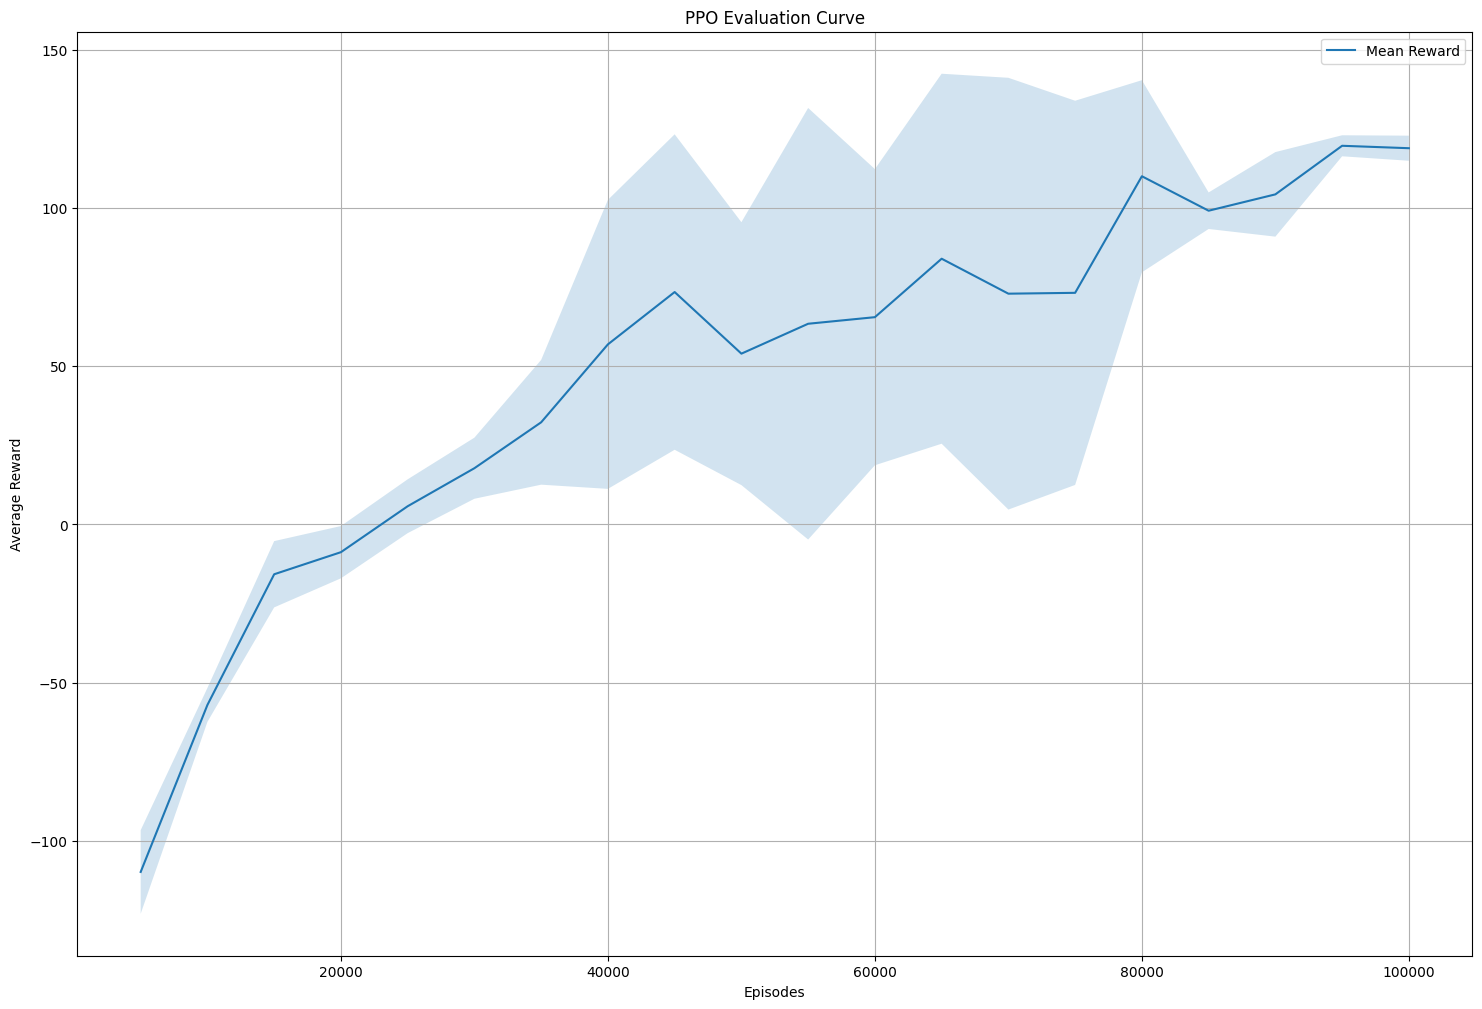

In [1]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 32
T_horizon = 2048
batch_size = 64
entropy_coef_i = 0.01
entropy_coef_e = 0.001
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

5000
-91.97694121347298
Time Taken until now: 0.8276638785998026 minutes
10000
-48.95931275417584
Time Taken until now: 1.752675680319468 minutes
15000
-2.696885699457893
Time Taken until now: 3.2267581105232237 minutes
20000
4.74713514349546
Time Taken until now: 4.614826560020447 minutes
25000
15.176834391563645
Time Taken until now: 6.372464426358541 minutes
30000
16.516564245522186
Time Taken until now: 8.004597322146099 minutes
35000
2.755800268049484
Time Taken until now: 9.791148161888122 minutes
40000
-25.13366748886052
Time Taken until now: 11.00852545897166 minutes
45000
-11.556621949186095
Time Taken until now: 12.640784303347269 minutes
50000
10.083991148638168
Time Taken until now: 15.069879154364267 minutes
55000
53.99805640195476
Time Taken until now: 17.742419997851055 minutes
60000
11.166474100162183
Time Taken until now: 19.48341336250305 minutes
65000
9.231179011930816
Time Taken until now: 21.405160534381867 minutes
70000
15.179811904027849
Time Taken until now: 23.

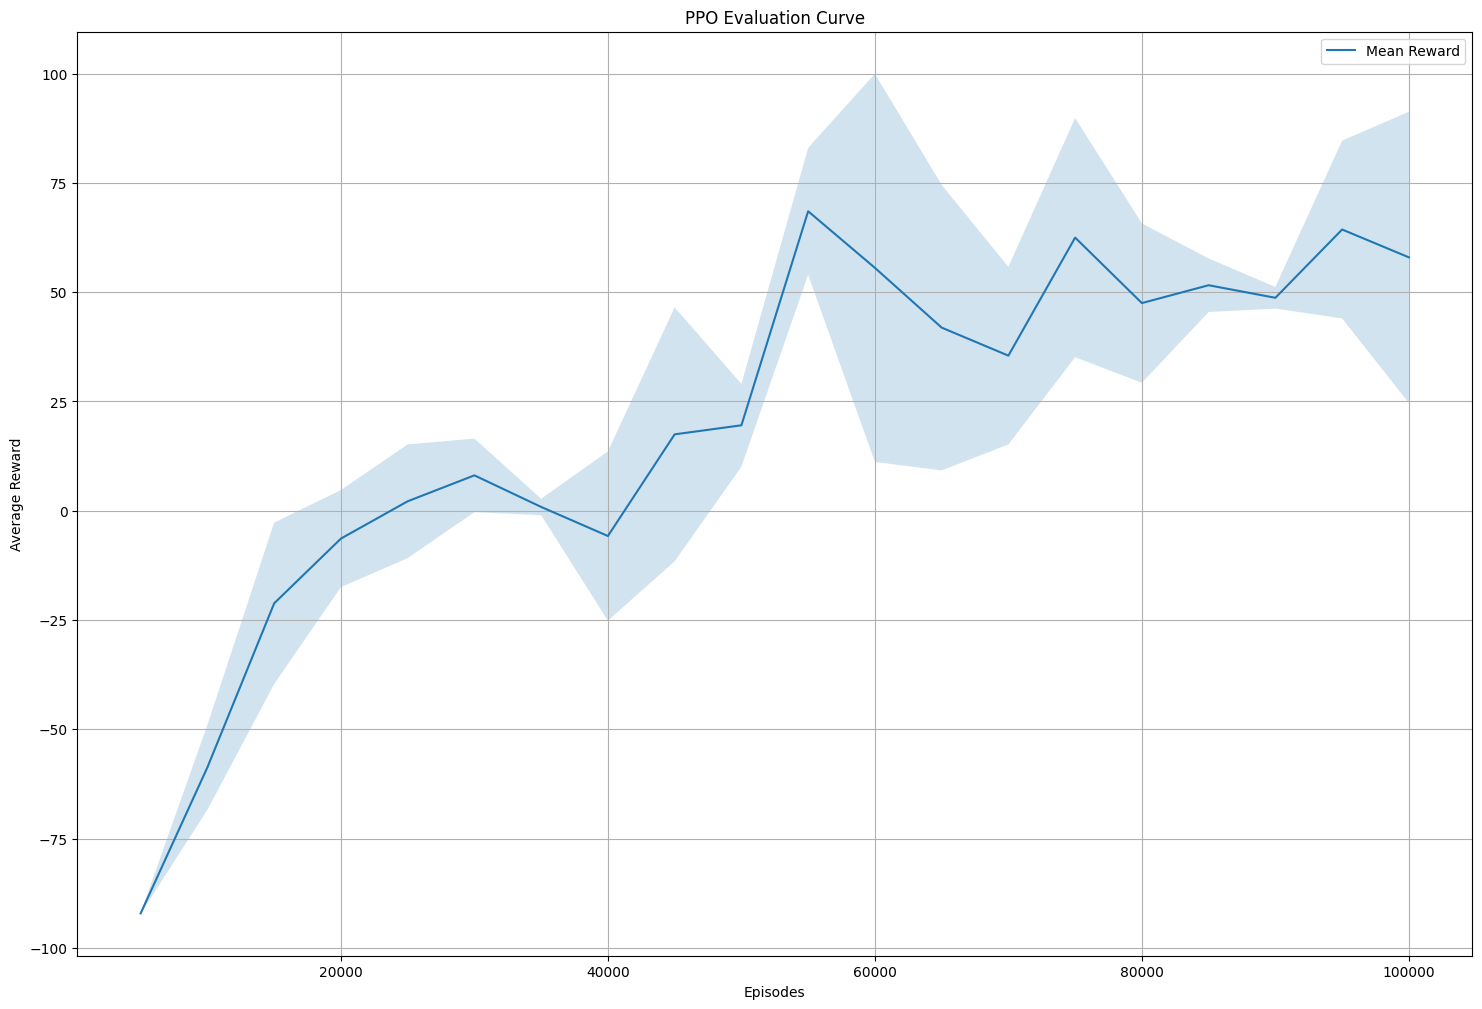

In [2]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 40
T_horizon = 2048
batch_size = 64
entropy_coef_i = 0.01
entropy_coef_e = 0.001
grad_clip = 0.5
max_timesteps = 100000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

7500
-82.68046224424135
Time Taken until now: 1.107295560836792 minutes
15000
-28.888578113420245
Time Taken until now: 2.5232786099116007 minutes
22500
7.888239165571897
Time Taken until now: 3.933130665620168 minutes
30000
32.2956766052512
Time Taken until now: 5.896445580323538 minutes
37500
16.425855906016146
Time Taken until now: 7.46375789642334 minutes
45000
22.859784681027413
Time Taken until now: 9.048581369717915 minutes
52500
-105.06268337980222
Time Taken until now: 10.501993441581726 minutes
60000
15.738940606515664
Time Taken until now: 12.521163074175517 minutes
67500
38.1700762625428
Time Taken until now: 14.646229231357575 minutes
75000
-70.4088384491054
Time Taken until now: 16.522568174203236 minutes
82500
-32.94770582344192
Time Taken until now: 18.34824401140213 minutes
90000
27.589020777473458
Time Taken until now: 19.92366267442703 minutes
97500
33.33291741008641
Time Taken until now: 21.57734442949295 minutes
105000
31.63299325092821
Time Taken until now: 23.080

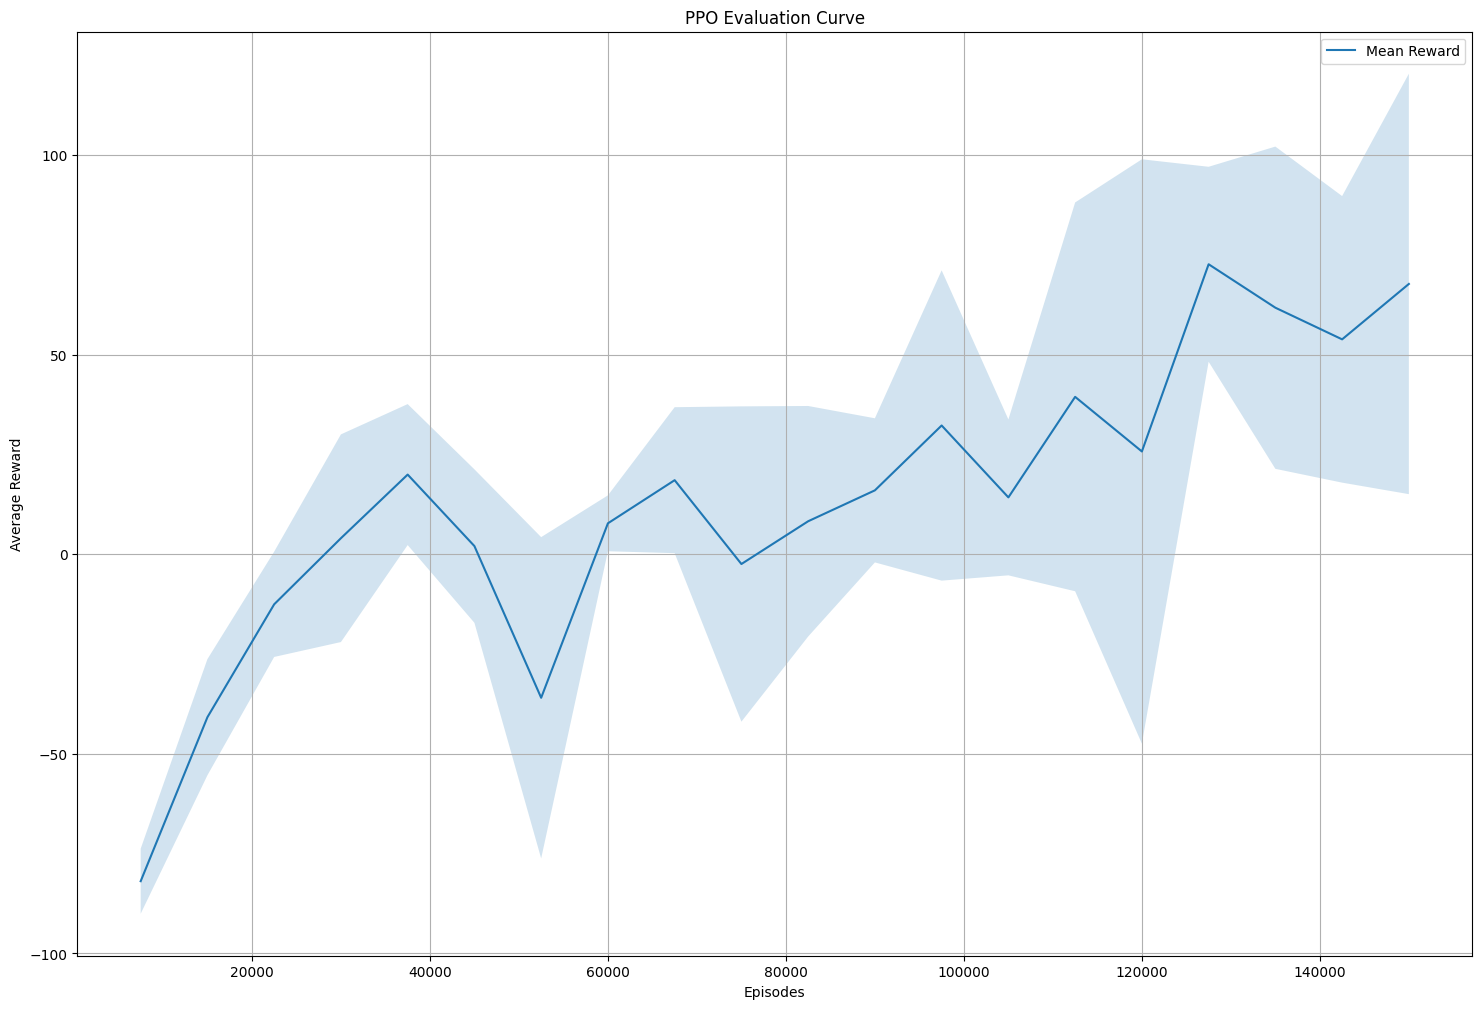

In [4]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate = 0.001
gamma = 0.999
lmbda = 0.95
eps_clip = 0.2
K_epochs = 24
T_horizon = 2048
batch_size = 32
entropy_coef_i = 0.01
entropy_coef_e = 0.001
grad_clip = 0.5
max_timesteps = 150000

# Build networks
def build_policy_network(state_dim, action_dim, action_std=None):
    model = nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std = nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)

# Env helpers
def reset_env(env):
    out = env.reset()
    return out if isinstance(out, tuple) else (out, {})

def step_env(env, action):
    out = env.step(action)
    if len(out) == 5:
        next_state, reward, terminated, truncated, info = out
        return next_state, reward, terminated or truncated, info
    next_state, reward, done, info = out
    return next_state, reward, done, info

# Action selection
def select_action(policy_net, state, is_continuous, log_std):
    state = torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means = policy_net(state)
    if is_continuous:
        std = log_std.exp()
        dist = torch.distributions.Normal(logits_or_means, std)
        action = torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs = torch.softmax(logits_or_means, dim=-1)
    dist = torch.distributions.Categorical(probs)
    action = dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# GAE
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages, gae = [], 0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * values[i+1] * (1 - dones[i]) - values[i]
        gae = delta + gamma * lmbda * (1 - dones[i]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states = torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions = torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs = torch.FloatTensor(memory['logprobs']).to(device)
    values = old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns = compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages = torch.FloatTensor(advantages).to(device)
    returns = torch.FloatTensor(returns).to(device)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    dataset = torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss = nn.MSELoss()

    for _ in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means = policy_net(s)
            if is_continuous:
                std = log_std.exp()
                dist = torch.distributions.Normal(logits_or_means, std)
                logprobs = dist.log_prob(a).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1)
            else:
                probs = torch.softmax(logits_or_means, dim=-1)
                dist = torch.distributions.Categorical(probs)
                logprobs = dist.log_prob(a)
                entropy = dist.entropy()

            state_values = value_net(s).squeeze()
            ratios = torch.exp(logprobs - old_lp)
            surr1 = ratios * adv
            surr2 = torch.clamp(ratios, 1 - eps_clip, 1 + eps_clip) * adv
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e)

            loss = -torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# Evaluation
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward = 0
    for _ in range(num_episodes):
        state, _ = reset_env(env)
        done = False
        while not done:
            action, _, _ = select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _ = step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    is_continuous = not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std = build_policy_network(state_dim, action_dim, action_std)
    value_net = build_value_network(state_dim)
    old_policy_net, _ = build_policy_network(state_dim, action_dim, action_std)
    old_value_net = build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

    optimizer = optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)

    memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start = time.time()

    while timestep < max_timesteps:
        state, _ = reset_env(env)
        done = False
        while not done:
            action, logprob, _ = select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, _ = step_env(env, action)

            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state = next_state
            timestep += 1
            if timestep % T_horizon == 0:
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory = {'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}

            if timestep % (max_timesteps//20)==0:
                print(timestep)
                eval_reward = evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")

            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',4)
plots(LL_ep,LL_mean,LL_sd)

7500
-95.64659217486061
Time Taken until now: 0.7867321093877157 minutes
15000
-42.751017714200316
Time Taken until now: 1.623273233572642 minutes
22500
-1.901117767439393
Time Taken until now: 2.707048149903615 minutes
30000
44.78863554495898
Time Taken until now: 4.845935662587483 minutes
37500
52.74612304475495
Time Taken until now: 6.767182083924611 minutes
45000
24.84745654141968
Time Taken until now: 8.152167936166128 minutes
52500
37.87075641652982
Time Taken until now: 9.783008722464244 minutes
60000
101.3893679591413
Time Taken until now: 12.918104668458303 minutes
67500
9.179536902849916
Time Taken until now: 16.211141701539358 minutes
75000
6.548287413079914
Time Taken until now: 19.80175055662791 minutes
82500
42.3972651297767
Time Taken until now: 23.264076137542723 minutes
90000
163.6156559754869
Time Taken until now: 24.869027062257132 minutes
97500
146.98752476305063
Time Taken until now: 26.255858755111696 minutes
105000
167.15571790618378
Time Taken until now: 27.5042

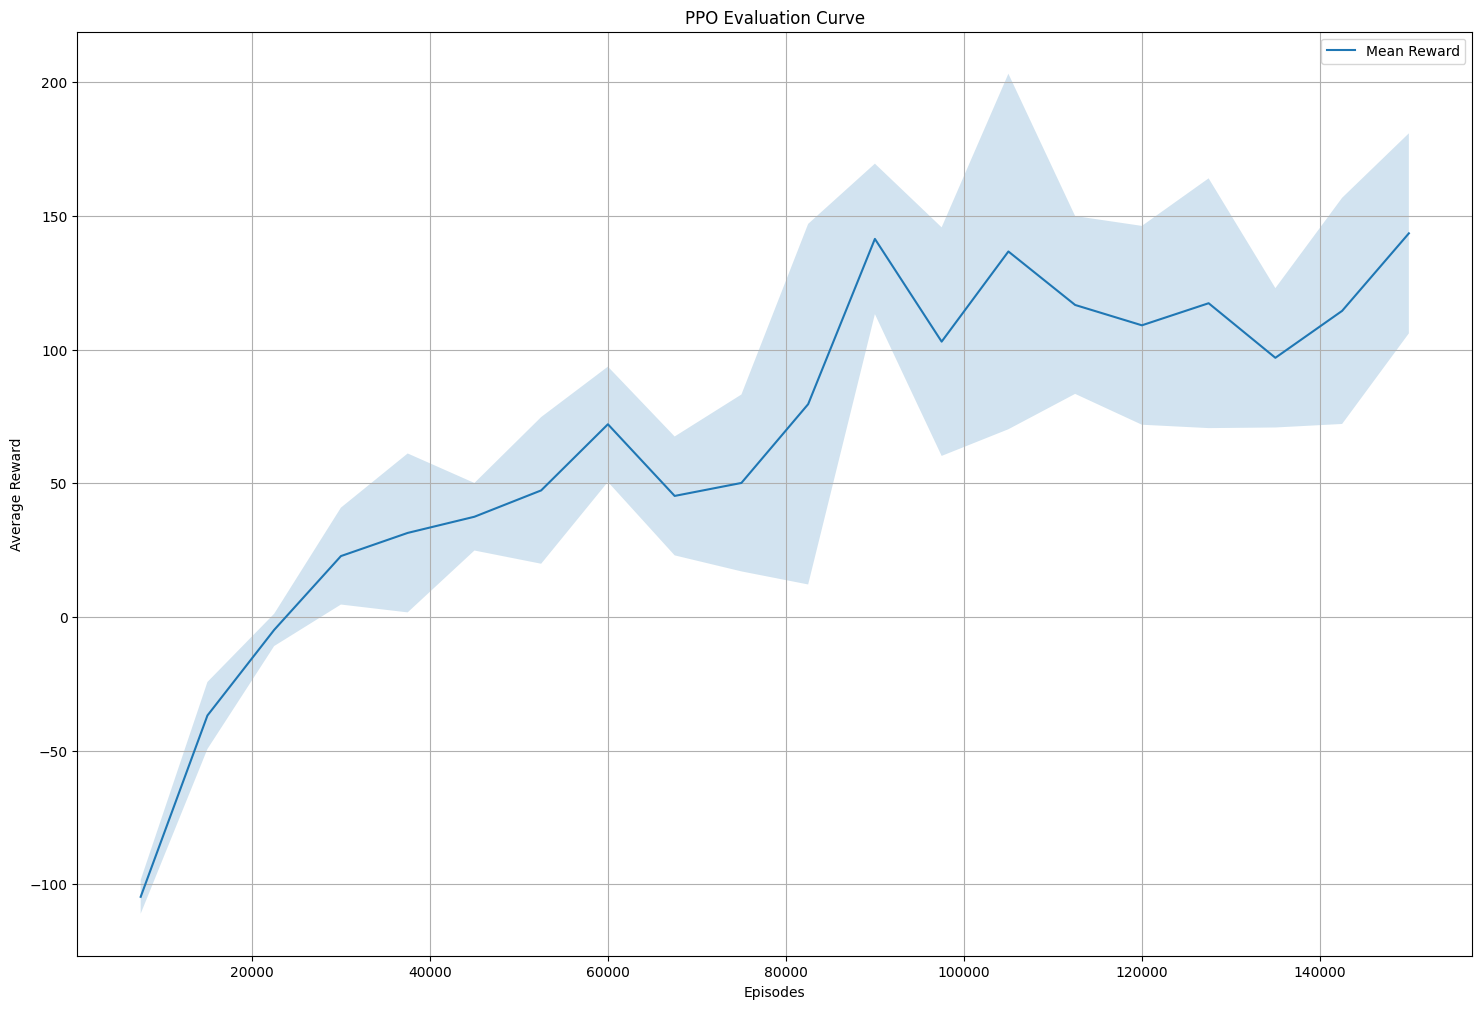

In [5]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# We try to take a chance to run on the GPUs if available
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate=0.001
gamma=0.999
lmbda=0.95
eps_clip=0.2
K_epochs=8
T_horizon=2048
batch_size=32
entropy_coef_i=0.01
entropy_coef_e=0.001
grad_clip=0.5
max_timesteps=150000

# We try to predict the probability distribution (just the numbers not probability as such, we convert into probabilities using softmax) of the actions posssible from a state
# We use ReLU for Lunar Lander and since the range of values for the actions in Swimmer is (-1,1) we use TanH as the activation functions
def build_policy_network(state_dim, action_dim, action_std=None):
    model=nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std=nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

# We try to predict the expected discounted rewards from a particular state to act as the critic
def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)
# Taking a step from a state
def step_env(env, action):
    next_state, reward, terminated, truncated, info=env.step(action)
    return next_state, reward, (terminated or truncated), info

# We select the action, The distinct action space are converted into probabilities using softmax and a action is selected from the distribution
# In continuous action spaces, we predict the mean value from the neural network above, we consider that the action space is gaussian and the standard deviation
# is also a parameter of the neural net, From the mean, std of a Gaussian distribution we sample the torque clipping its value within (-1,1)
def select_action(policy_net, state, is_continuous, log_std):
    state=torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means=policy_net(state)
    if is_continuous:
        std=log_std.exp()
        dist=torch.distributions.Normal(logits_or_means, std)
        action=torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob=dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs=torch.softmax(logits_or_means, dim=-1)
    dist=torch.distributions.Categorical(probs)
    action=dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# Generalized Adavantage is computed from backwards, using elibility traces lambda to get the best of both worlds, TD and Monte Carlo
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages=[]
    gae=0
    for i in reversed(range(len(rewards))):
        delta=rewards[i]+gamma*values[i+1]*(1-dones[i])-values[i]
        gae=delta+gamma*lmbda*(1-dones[i])*gae
        advantages.insert(0, gae)
    returns=[adv+val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update is done only after a specified horizon is reached.
# We do it for n epochs with our trajectory up until then.
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states=torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions=torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs=torch.FloatTensor(memory['logprobs']).to(device)
    values=old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns=compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages=torch.FloatTensor(advantages).to(device)
    returns=torch.FloatTensor(returns).to(device)
    advantages=(advantages-advantages.mean())/(advantages.std()+1e-8)  # Normalizing the advantages, Added a small number to the denominator to avoid diving with zero

    dataset=torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader=torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss=nn.MSELoss()

    for i in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means=policy_net(s)
            if is_continuous:
                std=log_std.exp()
                dist=torch.distributions.Normal(logits_or_means, std)
                logprobs=dist.log_prob(a).sum(dim=-1)
                entropy=dist.entropy().sum(dim=-1)
            else:
                probs=torch.softmax(logits_or_means, dim=-1)
                dist=torch.distributions.Categorical(probs)
                logprobs=dist.log_prob(a)
                entropy=dist.entropy()

            state_values=value_net(s).squeeze()
            ratios=torch.exp(logprobs - old_lp)
            surr1=ratios*adv
            surr2=torch.clamp(ratios, 1-eps_clip, 1+eps_clip)*adv # This is the distinctive feature of PPO, Clipping the objective
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e) # we try to annealate entropy coefficient over time, so we explore less as we progress

# Since we want to maximize the objective, minimize the mse loss between returns and the value of the state and again maximize the entropy
# and the optimizer tries to minimize the loss given to it, we add '-' before the terms we want to maximize
            
            loss=-torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy 
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# We try to evaluate the policy for every 5% completion of total time steps, we take an average of 200 runs.
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward=0
    for _ in range(num_episodes):
        state, info=env.reset()
        done=False
        while not done:
            action, _, _=select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _=step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env=gym.make(env_name)
    state_dim=env.observation_space.shape[0]
    is_continuous=not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std=build_policy_network(state_dim, action_dim, action_std)
    value_net=build_value_network(state_dim)
    old_policy_net, _=build_policy_network(state_dim, action_dim, action_std)
    old_value_net=build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())
    optimizer=optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)
    memory={'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start=time.time()

    while timestep < max_timesteps:
        state, info=env.reset()
        done=False
        while not done:
            action, logprob, _=select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, info=step_env(env, action)
            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state=next_state
            timestep+=1
            if timestep%T_horizon==0: # We update the PPO every T_horizon steps
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory={'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
            if timestep%(max_timesteps//20)==0: # We evaluate every 5% of our total number of steps
                print(timestep)
                eval_reward=evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")
            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',4)
plots(LL_ep,LL_mean,LL_sd)

## For policy networks, ReLU was used for Lunar Lander and TanH was used for Swimmer.
## This code runs and would generate the plots


In [7]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# We try to take a chance to run on the GPUs if available
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
learning_rate=0.001
gamma=0.999
lmbda=0.95
eps_clip=0.2
K_epochs=8
T_horizon=2048
batch_size=32
entropy_coef_i=0.01
entropy_coef_e=0.001
grad_clip=0.5
max_timesteps=100000

# We try to predict the probability distribution (just the numbers not probability as such, we convert into probabilities using softmax) of the actions posssible from a state
# We use ReLU for Lunar Lander and since the range of values for the actions in Swimmer is (-1,1) we use TanH as the activation functions
def build_policy_network(state_dim, action_dim, action_std=None):
    model=nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, action_dim)
    )
    if action_std is not None:
        log_std=nn.Parameter(torch.zeros(action_dim))
        return model.to(device), log_std.to(device)
    else:
        return model.to(device), None

# We try to predict the expected discounted rewards from a particular state to act as the critic
def build_value_network(state_dim):
    return nn.Sequential(
        nn.Linear(state_dim, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 1)
    ).to(device)
# Taking a step from a state
def step_env(env, action):
    next_state, reward, terminated, truncated, info=env.step(action)
    return next_state, reward, (terminated or truncated), info

# We select the action, The distinct action space are converted into probabilities using softmax and a action is selected from the distribution
# In continuous action spaces, we predict the mean value from the neural network above, we consider that the action space is gaussian and the standard deviation
# is also a parameter of the neural net, From the mean, std of a Gaussian distribution we sample the torque clipping its value within (-1,1)
def select_action(policy_net, state, is_continuous, log_std):
    state=torch.FloatTensor(state).unsqueeze(0).to(device)
    logits_or_means=policy_net(state)
    if is_continuous:
        std=log_std.exp()
        dist=torch.distributions.Normal(logits_or_means, std)
        action=torch.clamp(dist.sample(), -1.0, 1.0)
        log_prob=dist.log_prob(action).sum(dim=-1)
        return action.squeeze(0).cpu().numpy(), log_prob.item(), dist.entropy().sum()
    probs=torch.softmax(logits_or_means, dim=-1)
    dist=torch.distributions.Categorical(probs)
    action=dist.sample()
    return action.item(), dist.log_prob(action).item(), dist.entropy()

# Generalized Adavantage is computed from backwards, using elibility traces lambda to get the best of both worlds, TD and Monte Carlo
def compute_gae(rewards, dones, values, gamma, lmbda):
    values.append(0)
    advantages=[]
    gae=0
    for i in reversed(range(len(rewards))):
        delta=rewards[i]+gamma*values[i+1]*(1-dones[i])-values[i]
        gae=delta+gamma*lmbda*(1-dones[i])*gae
        advantages.insert(0, gae)
    returns=[adv+val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns

# PPO update is done only after a specified horizon is reached.
# We do it for n epochs with our trajectory up until then.
def ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,steps):
    states=torch.FloatTensor(np.array(memory['states'], dtype=np.float32)).to(device)
    actions=torch.FloatTensor(np.array(memory['actions'], dtype=np.float32) if is_continuous else np.array(memory['actions'])).to(device)
    old_logprobs=torch.FloatTensor(memory['logprobs']).to(device)
    values=old_value_net(states).squeeze().detach().cpu().numpy().tolist()
    advantages, returns=compute_gae(memory['rewards'], memory['dones'], values, gamma, lmbda)
    advantages=torch.FloatTensor(advantages).to(device)
    returns=torch.FloatTensor(returns).to(device)
    advantages=(advantages-advantages.mean())/(advantages.std()+1e-8)  # Normalizing the advantages, Added a small number to the denominator to avoid diving with zero

    dataset=torch.utils.data.TensorDataset(states, actions, old_logprobs, returns, advantages)
    loader=torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    mse_loss=nn.MSELoss()

    for i in range(K_epochs):
        for s, a, old_lp, ret, adv in loader:
            logits_or_means=policy_net(s)
            if is_continuous:
                std=log_std.exp()
                dist=torch.distributions.Normal(logits_or_means, std)
                logprobs=dist.log_prob(a).sum(dim=-1)
                entropy=dist.entropy().sum(dim=-1)
            else:
                probs=torch.softmax(logits_or_means, dim=-1)
                dist=torch.distributions.Categorical(probs)
                logprobs=dist.log_prob(a)
                entropy=dist.entropy()

            state_values=value_net(s).squeeze()
            ratios=torch.exp(logprobs - old_lp)
            surr1=ratios*adv
            surr2=torch.clamp(ratios, 1-eps_clip, 1+eps_clip)*adv # This is the distinctive feature of PPO, Clipping the objective
            entropy_coef=entropy_coef_i-(steps/max_timesteps)*(entropy_coef_i-entropy_coef_e) # we try to annealate entropy coefficient over time, so we explore less as we progress

# Since we want to maximize the objective, minimize the mse loss between returns and the value of the state and again maximize the entropy
# and the optimizer tries to minimize the loss given to it, we add '-' before the terms we want to maximize
            
            loss=-torch.min(surr1, surr2) + 0.5 * mse_loss(state_values, ret) - entropy_coef * entropy 
            optimizer.zero_grad()
            loss.mean().backward()
            torch.nn.utils.clip_grad_norm_(list(policy_net.parameters()) + list(value_net.parameters()), grad_clip)
            optimizer.step()
            scheduler.step()

    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())

# We try to evaluate the policy for every 5% completion of total time steps, we take an average of 200 runs.
def evaluate_policy(policy_net, env, is_continuous, log_std, num_episodes=200):
    total_reward=0
    for _ in range(num_episodes):
        state, info=env.reset()
        done=False
        while not done:
            action, _, _=select_action(policy_net, state, is_continuous, log_std)
            state, reward, done, _=step_env(env, action)
            total_reward += reward
    print(total_reward / num_episodes)
    return total_reward / num_episodes

# Training loop
def train(env_name):
    env=gym.make(env_name)
    state_dim=env.observation_space.shape[0]
    is_continuous=not isinstance(env.action_space, gym.spaces.Discrete)
    if is_continuous:
        action_dim=env.action_space.shape[0]
        action_std=0.5
    else:
        action_dim=env.action_space.n
        action_std=None

    policy_net, log_std=build_policy_network(state_dim, action_dim, action_std)
    value_net=build_value_network(state_dim)
    old_policy_net, _=build_policy_network(state_dim, action_dim, action_std)
    old_value_net=build_value_network(state_dim)
    old_policy_net.load_state_dict(policy_net.state_dict())
    old_value_net.load_state_dict(value_net.state_dict())
    optimizer=optim.Adam(list(policy_net.parameters()) + list(value_net.parameters()), lr=learning_rate)
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: 1 - step / max_timesteps)
    memory={'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
    timestep=0
    eval_rewards=[]
    eval_int=[]
    start=time.time()

    while timestep < max_timesteps:
        state, info=env.reset()
        done=False
        while not done:
            action, logprob, _=select_action(old_policy_net, state, is_continuous, log_std)
            next_state, reward, done, info=step_env(env, action)
            memory['states'].append(state)
            memory['actions'].append(action)
            memory['logprobs'].append(logprob)
            memory['rewards'].append(reward)
            memory['dones'].append(done)

            state=next_state
            timestep+=1
            if timestep%T_horizon==0: # We update the PPO every T_horizon steps
                ppo_update(policy_net, value_net, old_policy_net, old_value_net, optimizer, scheduler, memory, is_continuous, log_std,timestep)
                memory={'states': [], 'actions': [], 'logprobs': [], 'rewards': [], 'dones': []}
            if timestep%(max_timesteps//20)==0: # We evaluate every 5% of our total number of steps
                print(timestep)
                eval_reward=evaluate_policy(policy_net, env, is_continuous, log_std)
                eval_rewards.append(eval_reward)
                eval_int.append(timestep)
                print(f"Time Taken until now: {(time.time() - start)/60} minutes")
            if timestep >= max_timesteps:
                break

    env.close()
    return eval_int,eval_rewards, policy_net


def run_experiments(envi,n):
    rews=[]
    maxi=0
    final_neural=0
    for i in range(n):
        a,b,c=train(envi)
        if b[-1]>maxi:
            final_neural=c
        rews.append(b)
        
    episode_ct=a
    stacked_arrays=np.vstack(rews)
    means=np.mean(stacked_arrays, axis=0)
    sds=np.std(stacked_arrays, axis=0)
    return episode_ct,means,sds
    
def plots(episodes,means,sd):
    plt.figure(figsize=(18, 12))
    plt.plot(episodes, means, label='Mean Reward')
    plt.fill_between(episodes, means - sd, means + sd, alpha=0.2)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title(f'PPO Evaluation Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


LL_ep,LL_mean,LL_sd=run_experiments('LunarLander-v3',2)
plots(LL_ep,LL_mean,LL_sd)

KeyboardInterrupt: 